In [1]:
import os
os.environ["PATH"] = "/data/apps/extern/spack_on/gcc/9.3.0/texlive/20220321-oikenzl6gekq5lsohdm6jnnuj276s2ba/bin/x86_64-linux:" + os.environ.get("PATH", "")

from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from astropy.io import fits
from matplotlib.legend_handler import HandlerBase
from matplotlib.lines import Line2D
from matplotlib.patches import Rectangle


In [2]:
plt.rcParams.update({
    "text.usetex": True,
    "font.family": "serif",
    "font.size": 14,
})

REPO_ROOT = Path("/home/yzhan629/DS_MIRI")
NPZ_DIR = REPO_ROOT / "production" / "nirspec_candidates" / "npz"
PLOT_LAM_MAX_UM = 12.0
C_CGS = 2.99792458e10

# Change this to any file in NPZ_DIR
NPZ_PATH = NPZ_DIR / "JADES_GS_z14_0_joint_fit.npz"

# Display names + optional MIRI x1d (only z14-0 has MIRI spectroscopy)
TARGET_META = {
    "JADES_GS_z14_0": {
        "name": "JADES-GS-z14-0",
        "miri_x1d": REPO_ROOT / "data" / "jw08544_obsAll_t001_miri_p750l_x1d.fits",
    },
    "JADES_GS_z14_1": {"name": "JADES-GS-z14-1", "miri_x1d": None},
    "JADES_GS_z13": {"name": "JADES-GS-z13", "miri_x1d": None},
    "JADES_GS_z11": {"name": "JADES-GS-z11", "miri_x1d": None},
}


In [3]:
class _HandlerLineOverFill(HandlerBase):
    """Legend handle: gray band with spectrum line drawn through it."""

    def create_artists(
        self, legend, orig_handle, xdescent, ydescent, width, height, fontsize, trans,
    ):
        fill_color, line_color, line_lw = orig_handle
        band = Rectangle(
            (-xdescent, -ydescent), width, height,
            facecolor=fill_color, edgecolor="none", transform=trans,
        )
        midline = Line2D(
            [-xdescent, -xdescent + width],
            [-ydescent + 0.5 * height, -ydescent + 0.5 * height],
            color=line_color, lw=line_lw, transform=trans,
        )
        return [band, midline]


def jy_to_flambda_1e21(jy, wavelength_um):
    # Jy -> f_lambda [erg/s/cm^2/A] * 1e21
    f_nu = np.asarray(jy, float) * 1e-23
    lam_cm = np.asarray(wavelength_um, float) * 1e-4
    f_per_cm = f_nu * (C_CGS / lam_cm ** 2)
    return f_per_cm * 1e-8 * 1e21


def load_miri_x1d(path, lam_min_um=5.0, lam_max_um=PLOT_LAM_MAX_UM):
    # MIRI L3/Helton x1d EXTRACT1D: WAVELENGTH [um], FLUX/FLUX_ERROR [Jy]
    with fits.open(path) as hdul:
        spectrum = hdul["EXTRACT1D"].data
        wavelength_um = np.asarray(spectrum["WAVELENGTH"], float)
        flux_jy = np.asarray(spectrum["FLUX"], float)
        err_jy = np.asarray(spectrum["FLUX_ERROR"], float)
    flux_fl = jy_to_flambda_1e21(flux_jy, wavelength_um)
    err_fl = jy_to_flambda_1e21(err_jy, wavelength_um)
    # x1d often stores long -> short; sort blue -> red for plotting
    order = np.argsort(wavelength_um)
    wavelength_um = wavelength_um[order]
    flux_fl = flux_fl[order]
    err_fl = err_fl[order]
    good = (
        np.isfinite(wavelength_um) & np.isfinite(flux_fl) & np.isfinite(err_fl)
        & (err_fl > 0) & (wavelength_um >= lam_min_um) & (wavelength_um <= lam_max_um)
    )
    return wavelength_um[good], flux_fl[good], err_fl[good]

In [4]:
# Load fit products saved by nirspec_candidates_mp.py
data = np.load(NPZ_PATH, allow_pickle=True)
lam = data["lam"]
flux = data["flux"]
err = data["err"]
lam_plot = data["lam_plot"]
smds_plot = data["smds_plot"]
total_plot = data["total_plot"]
smds_flux = data["smds_flux"]  # model on observed lam grid
total_flux = data["total_flux"] if "total_flux" in data.files else smds_flux
z = float(data["z"])
log10M_ds = float(data["log10M_ds"])
mode = str(data["mode"])

galaxy_plot = data["galaxy_plot"] if "galaxy_plot" in data.files else None
total_plot_nm = (
    data["total_plot_nirspec_miri"] if "total_plot_nirspec_miri" in data.files else None
)
smds_plot_nm = (
    data["smds_plot_nirspec_miri"] if "smds_plot_nirspec_miri" in data.files else None
)
log10M_ds_nm = (
    float(data["log10M_ds_nirspec_miri"])
    if "log10M_ds_nirspec_miri" in data.files
    else None
)

# Infer label from filename: JADES_GS_z14_0_joint_fit.npz -> JADES_GS_z14_0
label = NPZ_PATH.name.replace("_joint_fit.npz", "").replace("_smds_fit.npz", "")
meta = TARGET_META.get(label, {"name": label, "miri_x1d": None})

# Optional MIRI stitch for observed spectrum (not stored in npz)
miri_lam = miri_flux = miri_err = None
miri_path = meta.get("miri_x1d")
if miri_path is not None and Path(miri_path).is_file():
    miri_lam, miri_flux, miri_err = load_miri_x1d(miri_path)
    stitch = miri_lam > float(np.max(lam))
    miri_lam, miri_flux, miri_err = miri_lam[stitch], miri_flux[stitch], miri_err[stitch]
    if miri_lam.size == 0:
        miri_lam = miri_flux = miri_err = None

print(f"{NPZ_PATH.name}: mode={mode}, z={z:.3f}, log10M_ds={log10M_ds:.2f}")
print("keys:", data.files)

JADES_GS_z14_0_joint_fit.npz: mode=joint, z=14.179, log10M_ds=6.18
keys: ['lam', 'flux', 'err', 'lam_plot', 'smds_flux', 'smds_plot', 'total_plot', 'z', 'R', 'log10M_ds', 'mode', 'galaxy_flux', 'total_flux', 'galaxy_plot', 'log10M_ds_nirspec_miri', 'smds_plot_nirspec_miri', 'total_plot_nirspec_miri', 'galaxy_plot_nirspec_miri']


/tmp/ipykernel_3659084/555509904.py:122: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


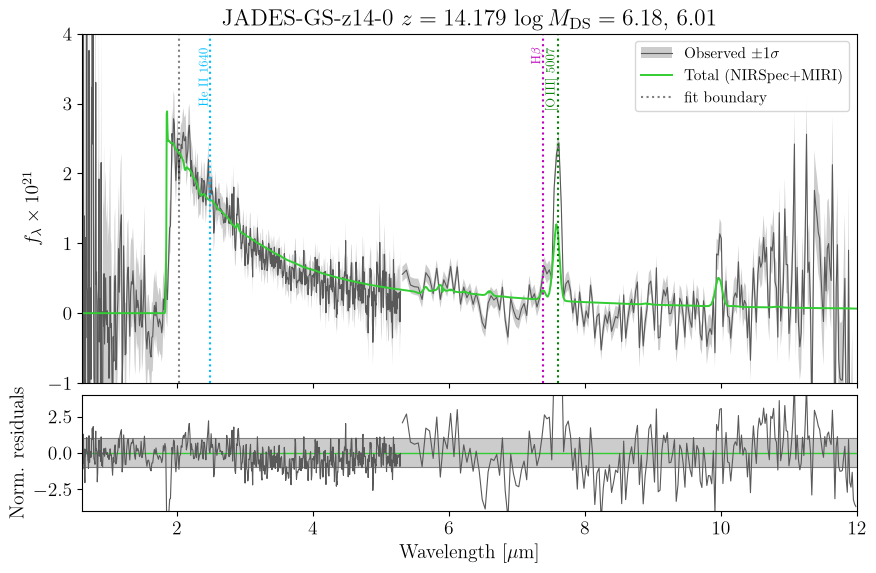

In [9]:
lya_cut = 1.10 * 0.1216 * (1.0 + z)

# Top: spectrum + models; bottom: data - model
fig, (ax, ax_resid) = plt.subplots(
    2, 1, figsize=(10, 6.2), sharex=True,
    gridspec_kw={"height_ratios": [3, 1], "hspace": 0.05},
)
ax.fill_between(
    lam, flux - err, flux + err,
    facecolor="0.8", edgecolor="none", linewidth=0,
)
ax.plot(lam, flux, lw=0.8, color="0.35")
if miri_lam is not None:
    ax.fill_between(
        miri_lam, miri_flux - miri_err, miri_flux + miri_err,
        facecolor="0.8", edgecolor="none", linewidth=0,
    )
    ax.plot(miri_lam, miri_flux, lw=0.8, color="0.35")

if mode == "joint":
    # ax.plot(
    #     lam_plot, galaxy_plot, lw=1, ls="-.", color="deepskyblue",
    #     label="Galaxy (NIRSpec)",
    # )
    # ax.plot(
    #     lam_plot, smds_plot, lw=1, ls="-.", color="darkviolet",
    #     label="SMDS (NIRSpec)",
    # )
    # ax.plot(
    #     lam_plot, total_plot, lw=1.2, ls="-", color="coral",
    #     label="Total (NIRSpec)",
    # )
    if total_plot_nm is not None:
        ax.plot(
            lam_plot, total_plot_nm, lw=1.4, ls="-", color="limegreen",
            label="Total (NIRSpec+MIRI)",
        )
else:
    ax.plot(
        lam_plot, smds_plot, lw=1.2, ls="-", color="darkviolet",
        label="SMDS (NIRSpec)",
    )
    if smds_plot_nm is not None:
        ax.plot(
            lam_plot, smds_plot_nm, lw=1.4, ls="--", color="limegreen",
            label="SMDS (NIRSpec+MIRI)",
        )

ax.axvline(lya_cut, ls=":", color="k", alpha=0.5, label="fit boundary")

spectral_lines = [
    (0.1640 * (1 + z), "deepskyblue", 1, r"He II 1640"),
    (0.4861 * (1 + z), "m", 1, r"H$\beta$"),
    (0.5007 * (1 + z), "g", 1, r"[O\,III] 5007"),
]
for lam_line, line_color, line_alpha, line_name in spectral_lines:
    ax.axvline(lam_line, ls=":", color=line_color, alpha=line_alpha)

ax.set_xlim(float(np.min(lam)), PLOT_LAM_MAX_UM)
ax.set_ylabel(r"$f_\lambda \times 10^{21}$")

if log10M_ds_nm is not None and f"{log10M_ds:.2f}" != f"{log10M_ds_nm:.2f}":
    mass_title = rf"$\log M_{{\rm DS}}={log10M_ds:.2f}$, ${log10M_ds_nm:.2f}$"
else:
    mass_title = rf"$\log M_{{\rm DS}}={log10M_ds:.2f}$"
ax.set_title(rf"{meta['name']}  $z={z:.3f}$  {mass_title}")

fit_peak = float(np.nanmax(total_plot))
if total_plot_nm is not None:
    fit_peak = max(fit_peak, float(np.nanmax(total_plot_nm)))
if miri_flux is not None and miri_flux.size:
    fit_peak = max(fit_peak, float(np.nanpercentile(miri_flux, 99)))
y_hi = fit_peak * 1.5
ax.set_ylim(-1, 4)

y_top = ax.get_ylim()[1] - 0.2
for lam_line, line_color, line_alpha, line_name in spectral_lines:
    ax.text(
        lam_line, y_top, line_name,
        color=line_color, alpha=line_alpha,
        rotation=90, va="top", ha="right", fontsize=9, clip_on=True,
    )

obs_proxy = ("0.8", "0.35", 0.8)  # fill, line color, line width
model_handles, model_labels = ax.get_legend_handles_labels()
ax.legend(
    handles=[obs_proxy] + model_handles,
    labels=[r"Observed $\pm 1\sigma$"] + model_labels,
    handler_map={tuple: _HandlerLineOverFill()},
    fontsize=11,
    ncol=1,
    loc="upper right",
)

# Normalized residuals; with MIRI, only the NIRSpec+MIRI combined-fit residual
nm_model_plot = total_plot_nm if mode == "joint" else smds_plot_nm
use_nm_resid = miri_lam is not None and nm_model_plot is not None
zero_color = "limegreen" if use_nm_resid else ("coral" if mode == "joint" else "darkviolet")
ax_resid.axhspan(-1.0, 1.0, facecolor="0.8", edgecolor="none")
ax_resid.axhline(1.0, color="0.5", lw=0.8, ls="-")
ax_resid.axhline(-1.0, color="0.5", lw=0.8, ls="-")
ax_resid.axhline(0.0, color=zero_color, lw=1.0, ls="-")

if use_nm_resid:
    model_nm_on_lam = np.interp(lam, lam_plot, nm_model_plot)
    norm_resid = (flux - model_nm_on_lam) / err
    ax_resid.plot(lam, norm_resid, lw=0.8, color="0.35")
    model_on_miri = np.interp(miri_lam, lam_plot, nm_model_plot)
    norm_resid_miri = (miri_flux - model_on_miri) / miri_err
    ax_resid.plot(miri_lam, norm_resid_miri, lw=0.8, color="0.35")
    resid_for_ylim = np.concatenate([norm_resid, norm_resid_miri])
else:
    norm_resid = (flux - total_flux) / err
    ax_resid.plot(lam, norm_resid, lw=0.8, color="0.35")
    resid_for_ylim = norm_resid

ax_resid.set_xlabel(r"Wavelength [$\mu$m]")
ax_resid.set_ylabel("Norm. residuals")
resid_span = float(np.nanpercentile(np.abs(resid_for_ylim), 98))
resid_span = max(resid_span, 4)
ax_resid.set_ylim(-resid_span, resid_span)
fig.tight_layout()

In [6]:
lam_rest_oiii_um = 0.5007
lam_rest_hbeta_um = 0.4861
lam_rest_heii_um = 0.1640


def miri_lrs_resolution(lam_um):
    # R~40 at 5 um to R~160 at 10 um (~100 at 7.5 um)
    resolving_power = 40.0 + (160.0 - 40.0) / (10.0 - 5.0) * (lam_um - 5.0)
    dlam_um = lam_um / resolving_power
    return resolving_power, dlam_um


def nirspec_prism_resolution(lam_um):
    # R~30 at 0.7 um to R~300 at 5 um (JWST NIRSpec PRISM/CLEAR)
    resolving_power = 30.0 + (300.0 - 30.0) / (5.0 - 0.7) * (lam_um - 0.7)
    dlam_um = lam_um / resolving_power
    return resolving_power, dlam_um


# Find peak between 7 and 8 um
peak_window = (miri_lam >= 7.0) & (miri_lam <= 8.0) & np.isfinite(miri_flux)
peak_index = int(np.nanargmax(miri_flux[peak_window]))
lam_peak_um = float(miri_lam[peak_window][peak_index])
R_peak, dlam_peak_um = miri_lrs_resolution(lam_peak_um)

# Assuming peak is [O III]
z_oiii = lam_peak_um / lam_rest_oiii_um - 1.0
sigma_z_oiii = dlam_peak_um / lam_rest_oiii_um
# Assuming peak is H beta
z_hbeta = lam_peak_um / lam_rest_hbeta_um - 1.0
sigma_z_hbeta = dlam_peak_um / lam_rest_hbeta_um


# Find dip between 2.5 and 2.7 um
dip_window = (lam >= 2.5) & (lam <= 2.7) & np.isfinite(flux)
dip_index = int(np.nanargmin(flux[dip_window]))
lam_dip_um = float(lam[dip_window][dip_index])
R_dip, dlam_dip_um = nirspec_prism_resolution(lam_dip_um)
dlam_dip_um = -dlam_dip_um
# Assume dip is [He II]
z_heii = lam_dip_um / lam_rest_heii_um - 1.0
sigma_z_heii = dlam_dip_um / lam_rest_heii_um

# # H beta: local max on the blue shoulder, left of the [O III] rise
# hbeta_window = (
#     (search_lam >= 7.2) & (search_lam <= 7.52) & np.isfinite(search_flux)
# )
# hbeta_peak_index = int(np.nanargmax(search_flux[hbeta_window]))
# lam_hbeta_um = float(search_lam[hbeta_window][hbeta_peak_index])
# z_hbeta = lam_hbeta_um / lam_rest_hbeta_um - 1.0
# R_hbeta, dlam_hbeta_um = miri_lrs_resolution(lam_hbeta_um)
# sigma_z_hbeta = dlam_hbeta_um / lam_rest_hbeta_um

print(f"Peak = {lam_peak_um:.4f} +/- {dlam_peak_um:.4f} um  (R={R_peak:.1f})")
print(f"Assuming peak is [O III] 5007, z = {z_oiii:.3f} +/- {sigma_z_oiii:.3f}")
print(f"Assuming peak is H beta 4861, z = {z_hbeta:.3f} +/- {sigma_z_hbeta:.3f}")
print(f"Assuming dip is [He II] 1640, z = {z_heii:.3f} +/- {sigma_z_heii:.3f}")
# print(f"H beta shoulder = {lam_hbeta_um:.4f} +/- {dlam_hbeta_um:.4f} um  (R={R_hbeta:.1f})")
# print(f"z(H beta) = {z_hbeta:.3f} +/- {sigma_z_hbeta:.3f}")
print(f"catalog z = {z:.4f}")

Peak = 7.6192 +/- 0.0741 um  (R=102.9)
Assuming peak is [O III] 5007, z = 14.217 +/- 0.148
Assuming peak is H beta 4861, z = 14.674 +/- 0.152
Assuming dip is [He II] 1640, z = 14.504 +/- -0.106
catalog z = 14.1793


/tmp/ipykernel_3659084/1957977288.py:113: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


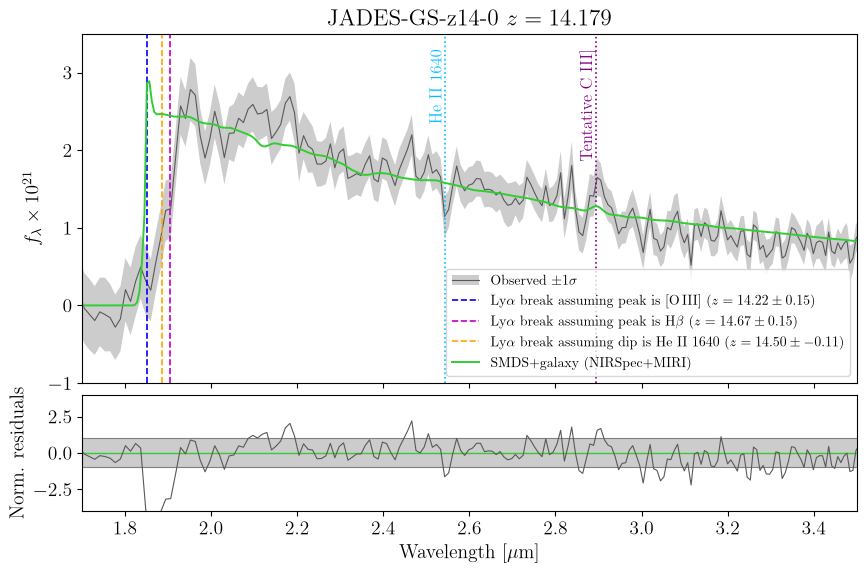

In [13]:
# Same spectrum plot, with Ly-alpha break from  z_oiii and z_hbeta
lam_lya_rest_um = 0.1216
lya_break_oiii = lam_lya_rest_um * (1.0 + z_oiii)
lya_break_hbeta = lam_lya_rest_um * (1.0 + z_hbeta)
lya_break_heii = lam_lya_rest_um * (1.0 + z_heii)

fig, (ax, ax_resid) = plt.subplots(
    2, 1, figsize=(10, 6.2), sharex=True,
    gridspec_kw={"height_ratios": [3, 1], "hspace": 0.05},
)
ax.fill_between(
    lam, flux - err, flux + err,
    facecolor="0.8", edgecolor="none", linewidth=0,
)
ax.plot(lam, flux, lw=0.8, color="0.35")

ax.axvline(
    lya_break_oiii, ls="--", color="blue", lw=1.2,
    label=rf"Ly$\alpha$ break assuming peak is [O\,III] ($z={z_oiii:.2f} \pm {sigma_z_oiii:.2f}$)",
)
ax.axvline(
    lya_break_hbeta, ls="--", color="m", lw=1.2,
    label=rf"Ly$\alpha$ break assuming peak is H$\beta$ ($z={z_hbeta:.2f} \pm {sigma_z_hbeta:.2f}$)",
)
ax.axvline(
    lya_break_heii, ls="--", color="orange", lw=1.2,
    label=rf"Ly$\alpha$ break assuming dip is He II 1640 ($z={z_heii:.2f} \pm {sigma_z_heii:.2f}$)",
)

spectral_lines = [
    (lam_dip_um, "deepskyblue", r"He II 1640"),
    (0.1907 * (1 + z), "purple", r"Tentative C III]"),
]
for lam_line, line_color, line_name in spectral_lines:
    ax.axvline(lam_line, ls=":", color=line_color, lw=1.2)

if miri_lam is not None:
    ax.fill_between(
        miri_lam, miri_flux - miri_err, miri_flux + miri_err,
        facecolor="0.8", edgecolor="none", linewidth=0,
    )
    ax.plot(miri_lam, miri_flux, lw=0.8, color="0.35")

if mode == "joint":
    if total_plot_nm is not None:
        ax.plot(
            lam_plot, total_plot_nm, lw=1.4, ls="-", color="limegreen",
            label="SMDS+galaxy (NIRSpec+MIRI)",
        )
else:
    ax.plot(
        lam_plot, smds_plot, lw=1.2, ls="-", color="darkviolet",
        label="SMDS (NIRSpec)",
    )
    if smds_plot_nm is not None:
        ax.plot(
            lam_plot, smds_plot_nm, lw=1.4, ls="--", color="limegreen",
            label="SMDS (NIRSpec+MIRI)",
        )

ax.set_xlim(float(np.min(lam)), PLOT_LAM_MAX_UM)
ax.set_ylabel(r"$f_\lambda \times 10^{21}$")
ax.set_ylim(-1, 3.5)
ax.set_title(rf"{meta['name']}  $z={z:.3f}$")

y_top = ax.get_ylim()[1] - 0.2
for lam_line, line_color, line_name in spectral_lines:
    ax.text(
        lam_line, y_top, line_name,
        color=line_color, alpha=line_alpha,
        rotation=90, va="top", ha="right", fontsize=12, clip_on=True,
    )

obs_proxy = ("0.8", "0.35", 0.8)
model_handles, model_labels = ax.get_legend_handles_labels()
ax.legend(
    handles=[obs_proxy] + model_handles,
    labels=[r"Observed $\pm 1\sigma$"] + model_labels,
    handler_map={tuple: _HandlerLineOverFill()},
    fontsize=10,
    ncol=1,
    loc="lower right",
)

nm_model_plot = total_plot_nm if mode == "joint" else smds_plot_nm
use_nm_resid = miri_lam is not None and nm_model_plot is not None
zero_color = "limegreen" if use_nm_resid else ("coral" if mode == "joint" else "darkviolet")
ax_resid.axhspan(-1.0, 1.0, facecolor="0.8", edgecolor="none")
ax_resid.axhline(1.0, color="0.5", lw=0.8, ls="-")
ax_resid.axhline(-1.0, color="0.5", lw=0.8, ls="-")
ax_resid.axhline(0.0, color=zero_color, lw=1.0, ls="-")

if use_nm_resid:
    model_nm_on_lam = np.interp(lam, lam_plot, nm_model_plot)
    norm_resid = (flux - model_nm_on_lam) / err
    ax_resid.plot(lam, norm_resid, lw=0.8, color="0.35")
    model_on_miri = np.interp(miri_lam, lam_plot, nm_model_plot)
    norm_resid_miri = (miri_flux - model_on_miri) / miri_err
    ax_resid.plot(miri_lam, norm_resid_miri, lw=0.8, color="0.35")
    resid_for_ylim = np.concatenate([norm_resid, norm_resid_miri])
else:
    norm_resid = (flux - total_flux) / err
    ax_resid.plot(lam, norm_resid, lw=0.8, color="0.35")
    resid_for_ylim = norm_resid


ax_resid.set_xlabel(r"Wavelength [$\mu$m]")
ax_resid.set_ylabel("Norm. residuals")
resid_span = float(np.nanpercentile(np.abs(resid_for_ylim), 98))
resid_span = max(resid_span, 4)
ax_resid.set_ylim(-resid_span, resid_span)
ax_resid.set_xlim(1.7, 3.5)
fig.tight_layout()